# Réseau Analogique — Disque — v8

## Correctifs vs v7

| Problème | Cause | Fix |
|---|---|---|
| `Fout ≈ constante` | Itot >> 1000 pA → saturation | **W_EXC limité par couche** (budget = I_max/N_in) |
| `ZeroDivisionError` | Filtre trop sévère, 0 mouvements | **Filtre supprimé** — pénalité dans score |

**Budget par synapse :** pour la couche l avec N_in entrées, on garde uniquement les W_EXC
tels que `Ipost(W, F_max) ≤ NEURON_I_MAX / N_in`. Même si toutes les entrées sont EXC au max, Itot reste dans la plage du neurone.

## 0. Imports & Configuration

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, warnings
warnings.filterwarnings('ignore')
from numba import njit, prange
import joblib
try:
    import cupy as cp; GPU_AVAILABLE = True
except: cp = None; GPU_AVAILABLE = False

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)

INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'
FREQ_MERGE_TOL_HZ = 1000.0

HIDDEN_SIZES = [8,8]

N_RESTARTS  = 8
N_ITER_SA   = 5000
TEMP_START  = 0.08
TEMP_END    = 1e-4
COOLING     = 'exponential'
SEED        = 42
N_JOBS      = -1

N_TRAIN = 400; N_TEST = 200; DISK_RADIUS = 0.5; MARGIN = 0.05
N_THRESHOLD_CANDIDATES = 50

MARGIN_SCALE       = 1e-5
IMBALANCE_PENALTY  = 0.0
MIN_MARGIN_HZ      = 1000.0
MIN_MARGIN_PENALTY = 0.1
MIN_ITOT_A         = -6e-12
MIN_ITOT_PENALTY   = 0.3
MAX_ITOT_PENALTY   = 1.0   # pénalité si Itot > I_neurone_max

NOISE_STD_HZ = 500.0
N_MC_EVAL    = 30

print('Configuration v8 OK.')

Configuration v8 OK.


## 1. Utilitaires

In [17]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty: raise ValueError(f"'{row_name}' introuvable")
        return pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(n, allow_non_numeric=True) for n in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm); return xm[o], ym[o]

def merge_close(values, tol):
    vals = np.sort(np.asarray(values, float)); groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol: groups[-1].append(v)
        else: groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap(values, axis):
    return np.array([axis[np.argmin(np.abs(axis-v))] for v in np.asarray(values,float)])

def build_grid(W_all, F_all, Y_all, tol=1000.0):
    W_all,F_all,Y_all=(np.asarray(a,float) for a in (W_all,F_all,Y_all))
    Wu=np.unique(W_all); Fa=merge_close(np.unique(F_all),tol); Fs=snap(F_all,Fa)
    g=np.empty((len(Wu),len(Fa)))
    for i,w in enumerate(Wu):
        for j,f in enumerate(Fa):
            m=np.isclose(W_all,w)&np.isclose(Fs,f); g[i,j]=np.mean(Y_all[m])
    return Wu,Fa,g

print('Utilitaires OK.')

Utilitaires OK.


## 2. Chargement + candidats par couche

In [18]:
inp = read_cadence_rows(INPUT_CSV)
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(inp('Vex'), inp('Fspikes'))
neuro = read_cadence_rows(NEURON_CSV)
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(neuro('Iex'), neuro('Fspikes'))
syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC,FPRE_EXC,IPOST_EXC),_ = get_clean_rows(syn_exc,['W2','Fpre','Ipost'])
W_EXC_AXIS,F_EXC_AXIS,IPOST_EXC_GRID = build_grid(W2_EXC,FPRE_EXC,IPOST_EXC)
syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH,FPRE_INH,IPOST_INH),_ = get_clean_rows(syn_inh,['W2','Fpre','Ipost'])
W_INH_AXIS,F_INH_AXIS,IPOST_INH_GRID = build_grid(W2_INH,FPRE_INH,IPOST_INH)

V_MIN=float(INPUT_V_AXIS[0]); V_MAX=float(INPUT_V_AXIS[-1])
NEURON_I_RHEOBASE=float(NEURON_I_AXIS[0]); NEURON_I_MAX=float(NEURON_I_AXIS[-1])
LAYER_SIZES=[2]+HIDDEN_SIZES+[1]; _F_MAX=float(NEURON_F_AXIS[-1])
MAX_ITOT_A = NEURON_I_MAX  # 1000 pA — plage max du neurone

_INPUT_V_AXIS  =np.ascontiguousarray(INPUT_V_AXIS,  np.float64)
_INPUT_F_AXIS  =np.ascontiguousarray(INPUT_F_AXIS,  np.float64)
_NEURON_I_AXIS =np.ascontiguousarray(NEURON_I_AXIS, np.float64)
_NEURON_F_AXIS =np.ascontiguousarray(NEURON_F_AXIS, np.float64)
_W_EXC_AXIS    =np.ascontiguousarray(W_EXC_AXIS,    np.float64)
_F_EXC_AXIS    =np.ascontiguousarray(F_EXC_AXIS,    np.float64)
_IPOST_EXC_GRID=np.ascontiguousarray(IPOST_EXC_GRID,np.float64)
_W_INH_AXIS    =np.ascontiguousarray(W_INH_AXIS,    np.float64)
_F_INH_AXIS    =np.ascontiguousarray(F_INH_AXIS,    np.float64)
_IPOST_INH_GRID=np.ascontiguousarray(IPOST_INH_GRID,np.float64)

# Candidats restreints : W_EXC limité par budget = I_max / N_in
ALL_CANDIDATES = []
for li,(n_in,n_out) in enumerate(zip(LAYER_SIZES[:-1],LAYER_SIZES[1:])):
    f_in_max = float(INPUT_F_AXIS[-1]) if li==0 else float(NEURON_F_AXIS[-1])
    budget = NEURON_I_MAX / n_in
    exc_ok = []
    for k,w in enumerate(W_EXC_AXIS):
        ipost = float(np.interp(f_in_max, F_EXC_AXIS, IPOST_EXC_GRID[k]))
        if ipost <= budget: exc_ok.append((+1, float(w)))
    if not exc_ok: exc_ok = [(+1, float(W_EXC_AXIS[0]))]
    ALL_CANDIDATES.append(exc_ok + [(-1,float(w)) for w in W_INH_AXIS])

print(f'Neurone : [{NEURON_I_AXIS[0]*1e12:.0f}, {NEURON_I_MAX*1e12:.0f}] pA | [{NEURON_F_AXIS[0]/1e3:.1f}, {_F_MAX/1e3:.1f}] kHz')
print(f'Architecture : {LAYER_SIZES}')
print('Candidats EXC par couche (budget I_max/N_in) :')
for li,(n_in,n_out) in enumerate(zip(LAYER_SIZES[:-1],LAYER_SIZES[1:])):
    ne=sum(1 for c in ALL_CANDIDATES[li] if c[0]==1)
    ni=sum(1 for c in ALL_CANDIDATES[li] if c[0]==-1)
    wm=max(c[1] for c in ALL_CANDIDATES[li] if c[0]==1)
    print(f'  L{li} ({n_in}→{n_out}): budget={NEURON_I_MAX/n_in*1e12:.0f}pA/syn → W_EXC≤{wm*1e3:.0f}mm : {ne} EXC + {ni} INH')

Neurone : [3, 1000] pA | [3.1, 193.1] kHz
Architecture : [2, 8, 8, 1]
Candidats EXC par couche (budget I_max/N_in) :
  L0 (2→8): budget=500pA/syn → W_EXC≤2548mm : 17 EXC + 20 INH
  L1 (8→8): budget=125pA/syn → W_EXC≤135mm : 1 EXC + 20 INH
  L2 (8→1): budget=125pA/syn → W_EXC≤135mm : 1 EXC + 20 INH


## 3. JIT batch

In [19]:
@njit
def _i1(x,xp,fp):
    if x<=xp[0]:return 0.
    if x>=xp[-1]:return fp[-1]
    lo,hi=0,len(xp)-1
    while hi-lo>1:
        m=(lo+hi)//2
        if xp[m]<=x:lo=m
        else:hi=m
    return fp[lo]+(x-xp[lo])/(xp[hi]-xp[lo])*(fp[hi]-fp[lo])

@njit
def _i2(x,y,xa,ya,g):
    x=max(xa[0],min(xa[-1],x));y=max(ya[0],min(ya[-1],y))
    lx=0
    for k in range(len(xa)-1):
        if xa[k]<=x<xa[k+1]:lx=k;break
    else:lx=len(xa)-2
    ly=0
    for k in range(len(ya)-1):
        if ya[k]<=y<ya[k+1]:ly=k;break
    else:ly=len(ya)-2
    tx=0. if xa[lx+1]==xa[lx] else (x-xa[lx])/(xa[lx+1]-xa[lx])
    ty=0. if ya[ly+1]==ya[ly] else (y-ya[ly])/(ya[ly+1]-ya[ly])
    return g[lx,ly]*(1-tx)*(1-ty)+g[lx+1,ly]*tx*(1-ty)+g[lx,ly+1]*(1-tx)*ty+g[lx+1,ly+1]*tx*ty

@njit(parallel=True)
def _fb(V,va,fa):
    S,D=V.shape;F=np.empty((S,D))
    for k in prange(S*D):F[k//D,k%D]=_i1(V[k//D,k%D],va,fa)
    return F

@njit(parallel=True)
def _lf(Fin,sf,wf,N,M,we,fe,ge,wi,fi,gi,ni,nf):
    S=Fin.shape[0];It=np.zeros((S,M))
    for k in prange(S*N*M):
        s=k//(N*M);nm=k%(N*M);i=nm//M;j=nm%M
        sg=sf[i*M+j];w=wf[i*M+j];f=Fin[s,i]
        if sg==1:It[s,j]+=_i2(w,f,we,fe,ge)
        elif sg==-1:It[s,j]-=_i2(w,f,wi,fi,gi)
    Fo=np.empty((S,M))
    for k in prange(S*M):Fo[k//M,k%M]=_i1(It[k//M,k%M],ni,nf)
    return Fo,It

def lyr(Fin,sm,wm):
    N,M=sm.shape
    return _lf(np.ascontiguousarray(Fin,np.float64),
               sm.ravel().astype(np.float64),wm.ravel().astype(np.float64),N,M,
               _W_EXC_AXIS,_F_EXC_AXIS,_IPOST_EXC_GRID,
               _W_INH_AXIS,_F_INH_AXIS,_IPOST_INH_GRID,
               _NEURON_I_AXIS,_NEURON_F_AXIS)

def net_fwd(V,signs,widths):
    F=_fb(np.ascontiguousarray(V,np.float64),_INPUT_V_AXIS,_INPUT_F_AXIS)
    itots=[]
    for sm,wm in zip(signs,widths):
        F,It=lyr(F,sm,wm);itots.append(It.ravel())
    return F[:,0],np.concatenate(itots)

print('Compilation JIT...')
t0=time.time()
_ds=np.array([[1.],[-1.]]);_dw=np.array([[float(W_EXC_AXIS[0])],[float(W_INH_AXIS[0])]])
_fb(np.zeros((5,2)),_INPUT_V_AXIS,_INPUT_F_AXIS)
lyr(np.ones((5,2))*1000.,_ds,_dw)
print(f'  JIT en {time.time()-t0:.1f}s')
_st=[np.ones((LAYER_SIZES[i],LAYER_SIZES[i+1])) for i in range(len(LAYER_SIZES)-1)]
_wt=[np.ones((LAYER_SIZES[i],LAYER_SIZES[i+1]))*W_EXC_AXIS[0] for i in range(len(LAYER_SIZES)-1)]
t0=time.perf_counter()
for _ in range(30): net_fwd(np.zeros((400,2)),_st,_wt)
tb=(time.perf_counter()-t0)/30
print(f'  Batch : {tb*1000:.2f} ms/éval  |  SA : ~{tb*N_ITER_SA*N_RESTARTS/60:.1f} min')

Compilation JIT...
  JIT en 1.0s
  Batch : 0.28 ms/éval  |  SA : ~0.2 min


## 4. Dataset

Train : 400 — int=68 (17%) ext=332


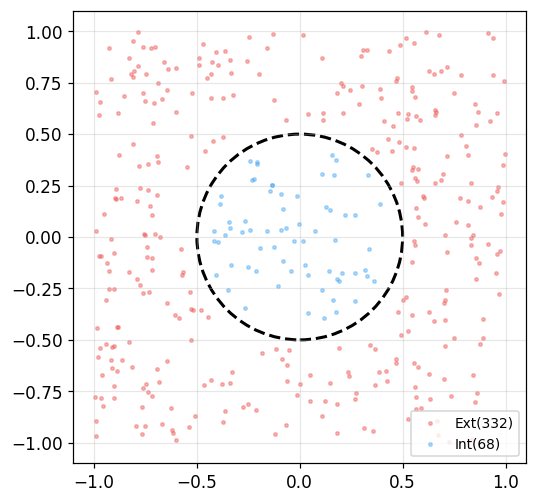

In [20]:
def make_ds(n,seed=0):
    rng=np.random.default_rng(seed);pts=[]
    while sum(len(p) for p in pts)<n:
        b=rng.uniform(-1.,1.,(n*2,2))
        pts.append(b[np.abs(np.sqrt(b[:,0]**2+b[:,1]**2)-DISK_RADIUS)>MARGIN])
    return np.vstack(pts)[:n]

def label(X): return (X[:,0]**2+X[:,1]**2<DISK_RADIUS**2).astype(int)
def xy2v(X):  return V_MIN+(np.asarray(X,float)+1.)*(V_MAX-V_MIN)/2.

X_tr=make_ds(N_TRAIN,SEED);y_tr=label(X_tr)
X_te=make_ds(N_TEST,SEED+1);y_te=label(X_te)
V_tr=np.ascontiguousarray(xy2v(X_tr),np.float64)
V_te=np.ascontiguousarray(xy2v(X_te),np.float64)
n1=y_tr.sum();n0=(1-y_tr).sum()
print(f'Train : {len(y_tr)} — int={n1} ({100*n1/len(y_tr):.0f}%) ext={n0}')
fig,ax=plt.subplots(figsize=(5,5))
ax.scatter(X_tr[y_tr==0,0],X_tr[y_tr==0,1],s=5,alpha=0.4,c='#EF5350',label=f'Ext({n0})')
ax.scatter(X_tr[y_tr==1,0],X_tr[y_tr==1,1],s=5,alpha=0.4,c='#42A5F5',label=f'Int({n1})')
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='k',fill=False,lw=2,ls='--'))
ax.set_aspect('equal');ax.set_xlim(-1.1,1.1);ax.set_ylim(-1.1,1.1)
ax.legend(fontsize=9);ax.grid(True,alpha=0.3);plt.tight_layout();plt.show()

## 5. Score

In [21]:
def find_thr(Fout,y,n=N_THRESHOLD_CANDIDATES):
    f0,f1=float(Fout.min()),float(Fout.max())
    if f1<=f0:return (f0+f1)/2,0.5
    cands=np.linspace(f0,f1,n+2)[1:-1];y=np.asarray(y,int);m0,m1=y==0,y==1
    bt,ba=cands[0],-1.
    for t in cands:
        p=(Fout>=t).astype(int)
        a=0.5*((np.mean(p[m0]==0) if m0.any() else 0.)+(np.mean(p[m1]==1) if m1.any() else 0.))
        if a>ba:ba,bt=a,t
    return bt,ba

def score_fn(Fout,itot,y,thr=None):
    y=np.asarray(y,int);m0,m1=y==0,y==1
    if thr is None:thr,_=find_thr(Fout,y)
    p=(Fout>=thr).astype(int)
    a0=float(np.mean(p[m0]==0)) if m0.any() else 0.
    a1=float(np.mean(p[m1]==1)) if m1.any() else 0.
    bal=0.5*(a0+a1)
    marg=np.where(y==1,Fout-thr,thr-Fout)
    bm=0.5*(np.mean(marg[m0])+np.mean(marg[m1]))
    fl=float(np.mean(marg<MIN_MARGIN_HZ))
    fi=float(np.mean(itot<MIN_ITOT_A))
    fx=float(np.mean(itot>MAX_ITOT_A))
    fr=(float(Fout.max())-float(Fout.min()))/1e3
    sc=bal+MARGIN_SCALE*bm-MIN_MARGIN_PENALTY*fl-MIN_ITOT_PENALTY*fi-MAX_ITOT_PENALTY*fx
    return sc,{'acc0':a0,'acc1':a1,'bal_acc':bal,'bal_margin':bm,'frac_below':fl,'frac_imin':fi,'frac_imax':fx,'fout_range_kHz':fr},thr

def evaluate(V,y,signs,widths,thr=None,noise_std=0.,n_mc=1):
    Fout,itot=net_fwd(V,signs,widths)
    if noise_std>0 and n_mc>1:
        rng2=np.random.default_rng()
        Fout=np.clip(Fout[None,:]+rng2.normal(0,noise_std,(n_mc,len(Fout))),0,_F_MAX).mean(0)
    sc,m,t=score_fn(Fout,itot,y,thr)
    return sc,m,t,Fout

def rand_net(rng):
    signs,widths=[],[]
    for li,(n_in,n_out) in enumerate(zip(LAYER_SIZES[:-1],LAYER_SIZES[1:])):
        cands=ALL_CANDIDATES[li]
        s=np.zeros((n_in,n_out));w=np.zeros((n_in,n_out))
        for i in range(n_in):
            for j in range(n_out):
                cs,cw=cands[rng.integers(len(cands))];s[i,j]=cs;w[i,j]=cw
        signs.append(s);widths.append(w)
    return signs,widths

def cp_net(s,w):return [x.copy() for x in s],[x.copy() for x in w]

def print_res(label,sc,m,thr):
    print(f'\n=== {label} ===')
    print(f'  seuil      = {thr*1e-3:.3f} kHz')
    print(f'  Fout range = {m["fout_range_kHz"]:.2f} kHz  (doit >> 1kHz)')
    print(f'  acc cl0    = {m["acc0"]:.4f}')
    print(f'  acc cl1    = {m["acc1"]:.4f}')
    print(f'  bal_acc    = {m["bal_acc"]:.4f}')
    print(f'  sat(>MAX)  = {m["frac_imax"]*100:.1f}%  (doit → 0%)')
    print(f'  score      = {sc:.6f}')

print('Score OK.')

Score OK.


## 6. Vérification candidats

In [22]:
rng_chk=np.random.default_rng(0);ranges=[];sat=[]
for _ in range(100):
    s,w=rand_net(rng_chk);Fout,itot=net_fwd(V_tr,s,w)
    ranges.append((Fout.max()-Fout.min())/1e3)
    sat.append(float(np.mean(itot>MAX_ITOT_A))*100)
print(f'100 configs aléatoires avec W_EXC restreint :')
print(f'  Fout range médian : {np.median(ranges):.2f} kHz')
print(f'  Fout range > 1kHz : {sum(1 for r in ranges if r>1)}/100')
print(f'  % saturé médian   : {np.median(sat):.1f}%')
if np.median(ranges)<0.5:
    print('⚠ Range trop faible — réduire HIDDEN_SIZES à [4,2]')
else:
    print('✓ Candidats OK — le SA peut explorer')

100 configs aléatoires avec W_EXC restreint :
  Fout range médian : 0.00 kHz
  Fout range > 1kHz : 19/100
  % saturé médian   : 0.0%
⚠ Range trop faible — réduire HIDDEN_SIZES à [4,2]


## 7. Simulated Annealing

In [23]:
def sa_run(restart_idx,rng_seed):
    rng=np.random.default_rng(rng_seed);R=f'R{restart_idx+1:02d}'
    signs,widths=rand_net(rng)
    sc,m,thr,_=evaluate(V_tr,y_tr,signs,widths)
    bs,bw=cp_net(signs,widths);best_sc=sc;best_thr=thr
    temps=(TEMP_START*(TEMP_END/TEMP_START)**(np.arange(N_ITER_SA)/(N_ITER_SA-1))
           if COOLING=='exponential' else np.linspace(TEMP_START,TEMP_END,N_ITER_SA))
    all_conns=[(l,i,j) for l,(n_in,n_out) in enumerate(zip(LAYER_SIZES[:-1],LAYER_SIZES[1:]))
               for i in range(n_in) for j in range(n_out)]
    log_every=max(1,N_ITER_SA//20);history=[];n_acc=0;t0=time.time()
    for it in range(N_ITER_SA):
        T=temps[it];l,i,j=all_conns[rng.integers(len(all_conns))]
        cands_l=ALL_CANDIDATES[l];cs,cw=cands_l[rng.integers(len(cands_l))]
        orig_s,orig_w=signs[l][i,j],widths[l][i,j]
        signs[l][i,j]=cs;widths[l][i,j]=cw
        new_sc,new_m,new_thr,_=evaluate(V_tr,y_tr,signs,widths)
        delta=new_sc-sc
        if delta>0 or rng.random()<np.exp(delta/T):
            sc,m,thr=new_sc,new_m,new_thr;n_acc+=1
            if sc>best_sc:best_sc=sc;best_thr=thr;bs,bw=cp_net(signs,widths)
        else:
            signs[l][i,j]=orig_s;widths[l][i,j]=orig_w
        if it%log_every==0 or it==N_ITER_SA-1:
            history.append({'iter':it,'T':T,'score':sc,'bal_acc':m['bal_acc'],
                            'best_sc':best_sc,'fout_range':m['fout_range_kHz'],'frac_imax':m['frac_imax']})
    elapsed=time.time()-t0
    sc_tr,m_tr,thr_tr,_=evaluate(V_tr,y_tr,bs,bw)
    sc_va,m_va,_,_=evaluate(V_te,y_te,bs,bw,thr=thr_tr)
    print(f'  {R} | tr={m_tr["bal_acc"]:.3f} va={m_va["bal_acc"]:.3f} | range={m_tr["fout_range_kHz"]:.1f}kHz | sat={m_tr["frac_imax"]*100:.0f}% | acc={n_acc/N_ITER_SA*100:.0f}% | {elapsed:.0f}s')
    return {'signs':bs,'widths':bw,'threshold':thr_tr,'tr_bal_acc':m_tr['bal_acc'],'va_bal_acc':m_va['bal_acc'],'tr_score':sc_tr,'va_score':sc_va,'history':history}

def run_sa():
    seeds=[SEED+r*1000 for r in range(N_RESTARTS)]
    print(f'SA : {N_RESTARTS}×{N_ITER_SA} — T:{TEMP_START}→{TEMP_END}')
    results=joblib.Parallel(n_jobs=N_JOBS,prefer='threads')(joblib.delayed(sa_run)(r,seeds[r]) for r in range(N_RESTARTS))
    best=max(results,key=lambda r:(r['va_bal_acc'],r['va_score']))
    print(f'\n★ va={best["va_bal_acc"]:.4f} tr={best["tr_bal_acc"]:.4f} seuil={best["threshold"]*1e-3:.2f}kHz')
    return best,results

print('SA OK.')

SA OK.


## 8. Entraînement

In [24]:
print(f'Architecture : {LAYER_SIZES} | Durée : ~{tb*N_ITER_SA*N_RESTARTS/60:.1f} min')
print()
t0=time.time()
best,all_results=run_sa()
print(f'Temps : {(time.time()-t0)/60:.1f} min')
signs=best['signs'];widths=best['widths'];best_thr=best['threshold']

Architecture : [2, 8, 8, 1] | Durée : ~0.2 min

SA : 8×5000 — T:0.08→0.0001
  R08 | tr=0.958 va=0.950 | range=3.4kHz | sat=0% | acc=38% | 39s  R02 | tr=0.948 va=0.966 | range=4.0kHz | sat=0% | acc=29% | 39s

  R04 | tr=0.946 va=0.931 | range=5.0kHz | sat=0% | acc=39% | 39s
  R05 | tr=0.979 va=0.984 | range=3.2kHz | sat=0% | acc=30% | 39s
  R03 | tr=0.902 va=0.934 | range=3.4kHz | sat=0% | acc=34% | 39s
  R07 | tr=0.866 va=0.847 | range=4.4kHz | sat=0% | acc=31% | 39s
  R06 | tr=0.852 va=0.847 | range=4.2kHz | sat=0% | acc=34% | 39s
  R01 | tr=0.992 va=0.975 | range=3.3kHz | sat=0% | acc=34% | 39s

★ va=0.9844 tr=0.9789 seuil=0.06kHz
Temps : 0.7 min


## 9. Résultats

In [25]:
sc_tr,m_tr,_,Fo_tr=evaluate(V_tr,y_tr,signs,widths,thr=best_thr)
sc_va,m_va,_,Fo_va=evaluate(V_te,y_te,signs,widths,thr=best_thr)
print_res('TRAIN (det)',sc_tr,m_tr,best_thr);print_res('TEST  (det)',sc_va,m_va,best_thr)
sc_tr_r,m_tr_r,_,_=evaluate(V_tr,y_tr,signs,widths,best_thr,NOISE_STD_HZ,N_MC_EVAL)
sc_va_r,m_va_r,_,_=evaluate(V_te,y_te,signs,widths,best_thr,NOISE_STD_HZ,N_MC_EVAL)
print_res('TRAIN (MC)',sc_tr_r,m_tr_r,best_thr);print_res('TEST  (MC)',sc_va_r,m_va_r,best_thr)


=== TRAIN (det) ===
  seuil      = 0.063 kHz
  Fout range = 3.22 kHz  (doit >> 1kHz)
  acc cl0    = 0.9578
  acc cl1    = 1.0000
  bal_acc    = 0.9789
  sat(>MAX)  = 0.0%  (doit → 0%)
  score      = 0.873321

=== TEST  (det) ===
  seuil      = 0.063 kHz
  Fout range = 3.22 kHz  (doit >> 1kHz)
  acc cl0    = 0.9688
  acc cl1    = 1.0000
  bal_acc    = 0.9844
  sat(>MAX)  = 0.0%  (doit → 0%)
  score      = 0.880361

=== TRAIN (MC) ===
  seuil      = 0.063 kHz
  Fout range = 3.26 kHz  (doit >> 1kHz)
  acc cl0    = 0.0000
  acc cl1    = 1.0000
  bal_acc    = 0.5000
  sat(>MAX)  = 0.0%  (doit → 0%)
  score      = 0.393418

=== TEST  (MC) ===
  seuil      = 0.063 kHz
  Fout range = 3.25 kHz  (doit >> 1kHz)
  acc cl0    = 0.0000
  acc cl1    = 1.0000
  bal_acc    = 0.5000
  sat(>MAX)  = 0.0%  (doit → 0%)
  score      = 0.395041


## 10. Courbes SA

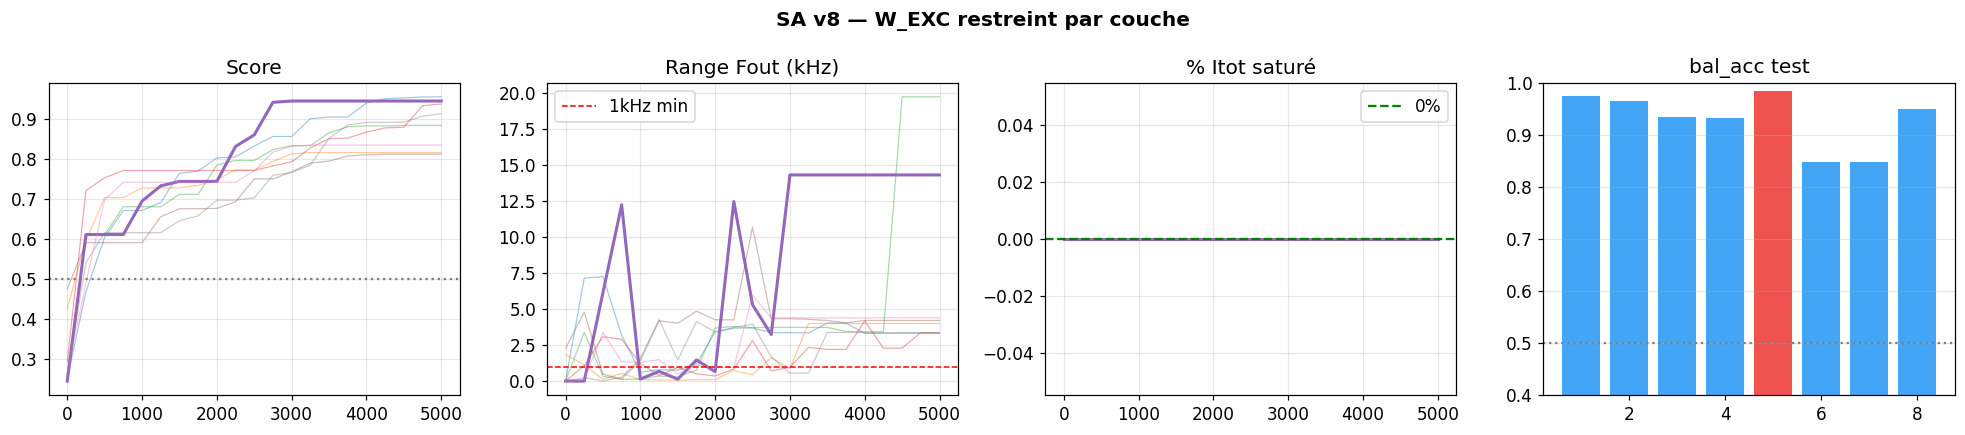

In [26]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
fig.suptitle(f'SA v8 — W_EXC restreint par couche',fontweight='bold')
ax=axes[0]
for r,res in enumerate(all_results):
    h=res['history'];iters=[x['iter'] for x in h]
    ax.plot(iters,[x['best_sc'] for x in h],lw=2 if res is best else 0.8,alpha=1. if res is best else 0.4)
ax.axhline(0.5,color='gray',ls=':');ax.set_title('Score');ax.grid(True,alpha=0.3)
ax=axes[1]
for res in all_results:
    h=res['history']
    ax.plot([x['iter'] for x in h],[x['fout_range'] for x in h],lw=2 if res is best else 0.8,alpha=1. if res is best else 0.4)
ax.axhline(1.,color='red',ls='--',lw=1,label='1kHz min');ax.set_title('Range Fout (kHz)');ax.legend();ax.grid(True,alpha=0.3)
ax=axes[2]
for res in all_results:
    h=res['history']
    ax.plot([x['iter'] for x in h],[x['frac_imax']*100 for x in h],lw=2 if res is best else 0.8,alpha=1. if res is best else 0.4)
ax.axhline(0,color='green',ls='--',lw=1.5,label='0%');ax.set_title('% Itot saturé');ax.legend();ax.grid(True,alpha=0.3)
ax=axes[3]
va=[r['va_bal_acc'] for r in all_results]
ax.bar(range(1,N_RESTARTS+1),va,color=['#EF5350' if r is best else '#42A5F5' for r in all_results])
ax.axhline(0.5,color='gray',ls=':');ax.set_title('bal_acc test');ax.set_ylim(0.4,1.);ax.grid(True,alpha=0.3,axis='y')
plt.tight_layout();plt.show()

## 11. Distribution + Carte

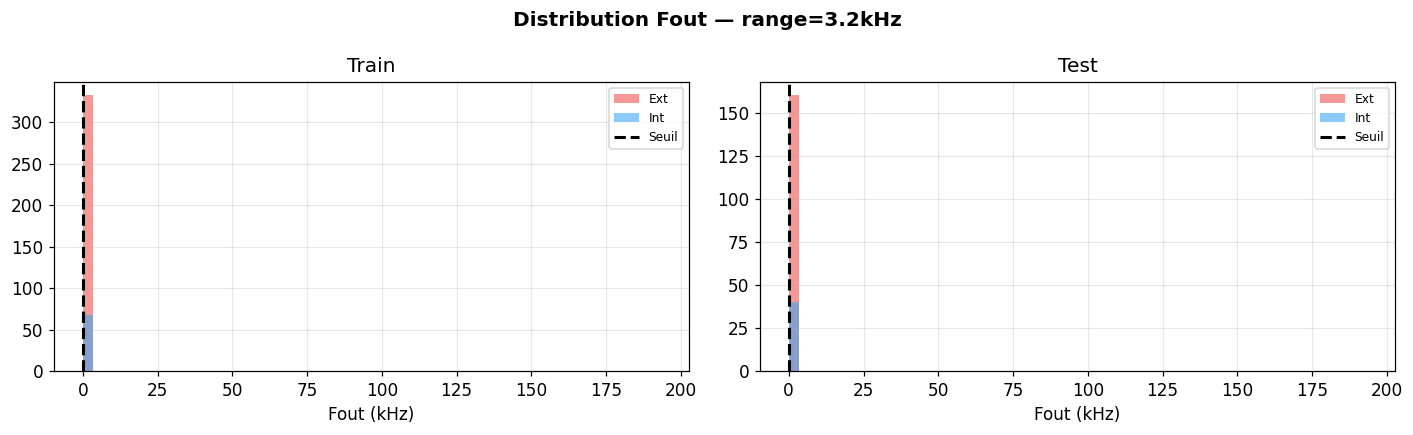

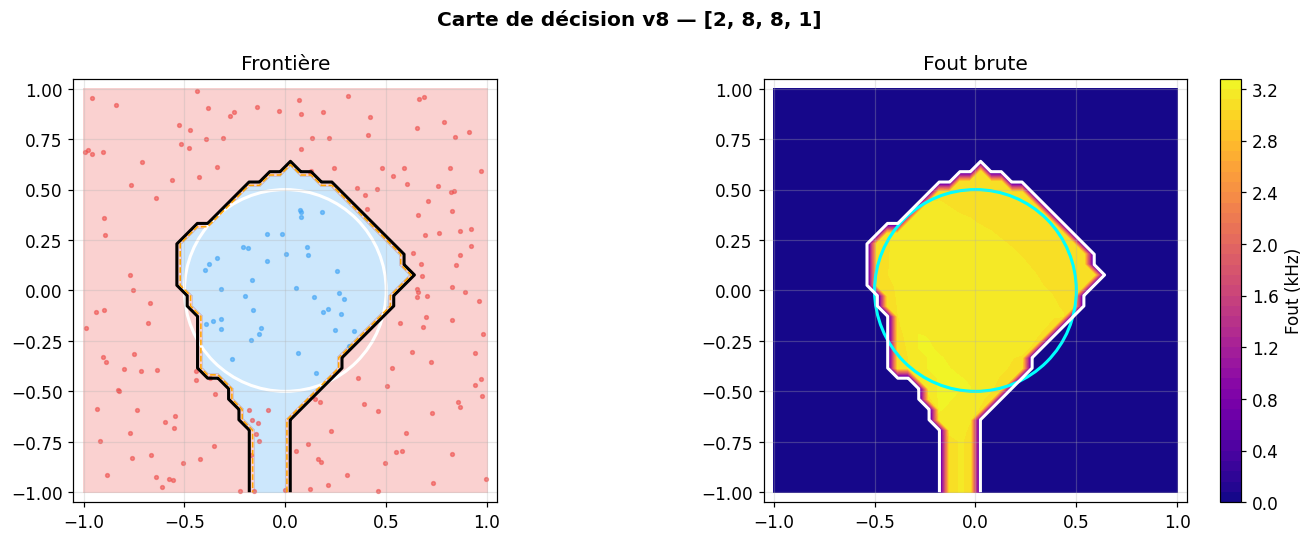

bal_acc test=0.9844  range=3.22kHz


In [27]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
fig.suptitle(f'Distribution Fout — range={m_tr["fout_range_kHz"]:.1f}kHz',fontweight='bold')
for ax,Fo,y,title in [(axes[0],Fo_tr,y_tr,'Train'),(axes[1],Fo_va,y_te,'Test')]:
    bins=np.linspace(0,_F_MAX,60)
    ax.hist(Fo[y==0]*1e-3,bins=bins*1e-3,alpha=0.6,color='#EF5350',label='Ext')
    ax.hist(Fo[y==1]*1e-3,bins=bins*1e-3,alpha=0.6,color='#42A5F5',label='Int')
    ax.axvline(best_thr*1e-3,color='k',lw=2,ls='--',label=f'Seuil')
    ax.set_xlabel('Fout (kHz)');ax.set_title(title);ax.legend(fontsize=8);ax.grid(True,alpha=0.3)
plt.tight_layout();plt.show()

res=40;xs=np.linspace(-1,1,res);XX,YY=np.meshgrid(xs,xs)
Vg=np.ascontiguousarray(xy2v(np.column_stack([XX.ravel(),YY.ravel()])),np.float64)
Fg,_=net_fwd(Vg,signs,widths);pred=(Fg>=best_thr).astype(int).reshape(XX.shape)
dg=(Fg.reshape(XX.shape)-best_thr)*1e-3
fig,axes=plt.subplots(1,2,figsize=(13,5))
fig.suptitle(f'Carte de décision v8 — {LAYER_SIZES}',fontweight='bold')
ax=axes[0]
ax.contourf(XX,YY,pred,levels=[-0.5,0.5,1.5],colors=['#EF535044','#42A5F544'])
ax.contour(XX,YY,dg,levels=[0],colors='k',linewidths=2)
ax.contour(XX,YY,dg,levels=[-1,1],colors='orange',linewidths=1,linestyles='--')
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='white',fill=False,lw=2))
ax.scatter(X_te[y_te==0,0],X_te[y_te==0,1],s=6,c='#EF5350',alpha=0.6)
ax.scatter(X_te[y_te==1,0],X_te[y_te==1,1],s=6,c='#42A5F5',alpha=0.6)
ax.set_title('Frontière');ax.set_aspect('equal');ax.set_xlim(-1.05,1.05);ax.set_ylim(-1.05,1.05);ax.grid(True,alpha=0.3)
ax=axes[1]
cf=ax.contourf(XX,YY,Fg.reshape(XX.shape)*1e-3,levels=50,cmap='plasma')
plt.colorbar(cf,ax=ax,label='Fout (kHz)')
ax.contour(XX,YY,dg,levels=[0],colors='white',linewidths=2)
ax.add_patch(plt.Circle((0,0),DISK_RADIUS,color='cyan',fill=False,lw=2))
ax.set_title('Fout brute');ax.set_aspect('equal');ax.set_xlim(-1.05,1.05);ax.set_ylim(-1.05,1.05);ax.grid(True,alpha=0.3)
plt.tight_layout();plt.show()
print(f'bal_acc test={m_va["bal_acc"]:.4f}  range={m_va["fout_range_kHz"]:.2f}kHz')

## 12. Diagnostic Itot

In [28]:
print('='*60+f'\n  DIAGNOSTIC Itot — plage neurone [{NEURON_I_AXIS[0]*1e12:.0f}, {NEURON_I_MAX*1e12:.0f}] pA\n'+'='*60)
F=_fb(V_tr,_INPUT_V_AXIS,_INPUT_F_AXIS)
for li,(sm,wm) in enumerate(zip(signs,widths)):
    F,It=lyr(F,sm,wm);it=It.ravel()
    pi=100*np.mean(it<MIN_ITOT_A);px=100*np.mean(it>MAX_ITOT_A);ps=100*np.mean((it>=0)&(it<NEURON_I_RHEOBASE))
    print(f'  L{li}: [{it.min()*1e12:.0f},{it.max()*1e12:.0f}]pA  <MIN:{pi:.1f}%  >MAX:{px:.1f}%  silencieux:{ps:.1f}%')
print('='*60)

  DIAGNOSTIC Itot — plage neurone [3, 1000] pA
  L0: [-17,857]pA  <MIN:5.3%  >MAX:0.0%  silencieux:16.1%
  L1: [-139,116]pA  <MIN:21.4%  >MAX:0.0%  silencieux:17.9%
  L2: [-1,3]pA  <MIN:0.0%  >MAX:0.0%  silencieux:73.2%


## 13. Export

In [29]:
rows=[]
for li,(s,w) in enumerate(zip(signs,widths)):
    si=s.astype(int)
    for i in range(si.shape[0]):
        for j in range(si.shape[1]):
            rows.append({'layer':li+1,'pre':i,'post':j,'sign':int(si[i,j]),'width_um':float(w[i,j]),'type':'EXC' if si[i,j]==1 else 'INH'})
df_w=pd.DataFrame(rows);df_w.to_csv('weights_cadence_disk_v8.csv',index=False)
pd.DataFrame([{'threshold_Hz':best_thr,'threshold_kHz':best_thr*1e-3,'bal_acc_train':m_tr['bal_acc'],'bal_acc_test':m_va['bal_acc'],'fout_range_kHz':m_tr['fout_range_kHz']}]).to_csv('threshold_cadence_disk_v8.csv',index=False)
print(df_w.to_string(index=False))
print(f'\nseuil={best_thr*1e-3:.3f}kHz  bal_acc train={m_tr["bal_acc"]:.4f} test={m_va["bal_acc"]:.4f}')
# Affichage détaillé par couche
layer_names = (['In->H1']
               + [f'H{k}->H{k+1}' for k in range(1, len(signs)-1)]
               + [f'H{len(signs)-1}->Out'])

print(f'\n=== POIDS FINAUX {LAYER_SIZES} — seuil={best_thr*1e-3:.3f} kHz ===')
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    si = s.astype(int)
    print(f'\n  Couche {k+1} [{ln}]  {si.shape[0]}→{si.shape[1]}')
    print(f'    Signes :\n{si}')
    print(f'    Largeurs (µm) :\n{w}')
    print(f'    EXC={int((si==1).sum())}  INH={int((si==-1).sum())}')

# Export CSV
rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    si = s.astype(int)
    for i in range(si.shape[0]):
        for j in range(si.shape[1]):
            rows.append({'layer':li+1,'pre':i,'post':j,
                         'sign':int(si[i,j]),'width_um':float(w[i,j]),
                         'type':'EXC' if si[i,j]==1 else 'INH'})

df_w = pd.DataFrame(rows)
df_w.to_csv('weights_cadence_disk_v8.csv', index=False)
pd.DataFrame([{'threshold_Hz':best_thr,'threshold_kHz':best_thr*1e-3,
               'bal_acc_train':m_tr['bal_acc'],'bal_acc_test':m_va['bal_acc']}]
             ).to_csv('threshold_cadence_disk_v8.csv', index=False)

print('\n--- CSV ---')
print(df_w.to_string(index=False))
print(f'\nseuil={best_thr*1e-3:.3f}kHz  bal_acc train={m_tr["bal_acc"]:.4f} test={m_va["bal_acc"]:.4f}')

 layer  pre  post  sign  width_um type
     1    0     0    -1    0.9089  INH
     1    0     1    -1    0.8179  INH
     1    0     2     1    1.9440  EXC
     1    0     3    -1    0.3171  INH
     1    0     4     1    1.7940  EXC
     1    0     5    -1    0.5903  INH
     1    0     6     1    1.1910  EXC
     1    0     7     1    0.5874  EXC
     1    1     0    -1    0.7268  INH
     1    1     1    -1    0.5447  INH
     1    1     2     1    2.5480  EXC
     1    1     3    -1    0.8634  INH
     1    1     4    -1    0.3171  INH
     1    1     5     1    2.0950  EXC
     1    1     6    -1    0.5447  INH
     1    1     7     1    1.3410  EXC
     2    0     0    -1    0.1805  INH
     2    0     1    -1    0.4082  INH
     2    0     2    -1    0.5903  INH
     2    0     3     1    0.1350  EXC
     2    0     4    -1    1.0000  INH
     2    0     5    -1    1.0000  INH
     2    0     6    -1    0.7268  INH
     2    0     7    -1    0.4082  INH
     2    1     0    -1  

## Annexe — Dépannage

| Symptôme | Fix |
|---|---|
| `Fout range < 0.5kHz` | `HIDDEN_SIZES = [4, 2]` (moins de saturation) |
| `% saturé > 10%` | `MAX_ITOT_PENALTY = 3.0` |
| `bal_acc ≈ 0.5` | `N_ITER_SA = 10000` ou `HIDDEN_SIZES = [12, 6]` |
| Frontière en arc | `N_RESTARTS = 16`, `TEMP_START = 0.15` |